# 01. Quickstart — AutoHybTS

Forecasting a univariate series: AutoHybTS compares standalone models and residual hybrids (base model + error corrector) and accepts the hybrid only when it proves a gain in temporal validation. Otherwise, it keeps the simpler model.

- Input: a `pandas.Series` with a regular time index.
- `fh` is the forecast horizon (number of steps ahead).

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc2


## 1. Load the data

In [2]:
from autohybts.datasets import get_data

y = get_data("synthetic_daily")
y.tail()

2025-12-26    69.786655
2025-12-27    68.674617
2025-12-28    70.105403
2025-12-29    71.148468
2025-12-30    72.611886
Freq: D, Name: value, dtype: float64

## 2. Fit the experiment

`fit` validates the series (order, duplicates, frequency), holds back the last `fh` points as the **sealed test** and freezes the validation origins. Nothing that comes after sees the sealed test, until the final evaluation in section 5.

In [3]:
from autohybts import AutoHybridExperiment

exp = AutoHybridExperiment(fh=14, session_id=42).fit(y)
exp.splits

,layer,train_start,origin,first_target,last_target,n_train,horizon
fold_id,,,,,,,
search-0,search,2024-01-01,2025-06-03,2025-06-04,2025-06-17,520,14
search-1,search,2024-01-01,2025-06-17,2025-06-18,2025-07-01,534,14
search-2,search,2024-01-01,2025-07-01,2025-07-02,2025-07-15,548,14
search-3,search,2024-01-01,2025-07-15,2025-07-16,2025-07-29,562,14
search-4,search,2024-01-01,2025-07-29,2025-07-30,2025-08-12,576,14
search-5,search,2024-01-01,2025-08-12,2025-08-13,2025-08-26,590,14
search-6,search,2024-01-01,2025-08-26,2025-08-27,2025-09-09,604,14
select-0,select,2024-01-01,2025-09-09,2025-09-10,2025-09-23,618,14
select-1,select,2024-01-01,2025-09-23,2025-09-24,2025-10-07,632,14


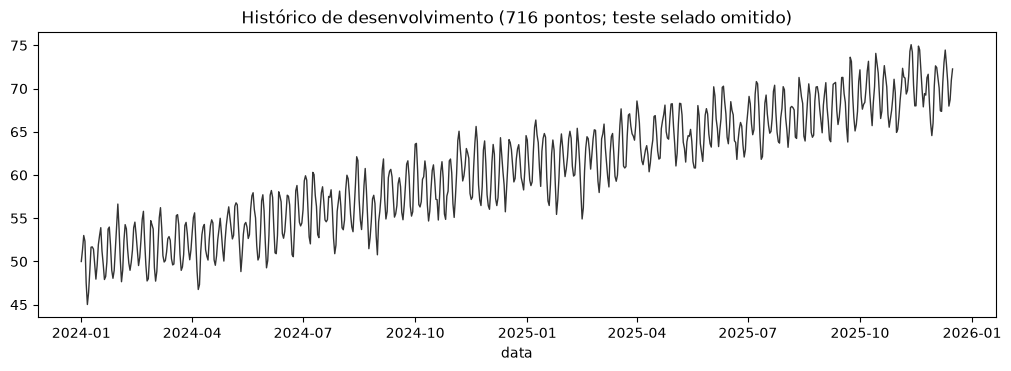

In [4]:
exp.plot_data("series")

## 3. Compare models

In [5]:
result = exp.compare_models()
result.leaderboard

,name,model,family,strategy,base,corrector,residual_source,window,alpha,mean_rank,...,MAE,RMSE,sMAPE,coverage,n_units,n_failed,n_skipped,fit_seconds,predict_seconds,is_champion
candidate_id,,,,,,,,,,,,,,,,,,,,,
7dd1082a4ee4fe9df20683376c5688b4a23322240929c4c44a8140e266a10ae2,mlp,mlp(lags=7),neural,standalone,mlp,NaN,NaN,NaN,NaN,1.0,...,1.352722,1.607530,0.020369,1.0,7,0,0,0.475421,0.009633,False
c4821c0a39e39a26ca17be31d8298f1ebcaed90d98e0a1fd3722f7c6ed592f9b,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,0.5,2.0,...,1.372676,1.629758,0.020592,1.0,7,0,0,0.425164,0.016391,False
e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4,linear,linear(lags=7),linear,standalone,linear,NaN,NaN,NaN,NaN,3.0,...,1.377221,1.630795,0.020681,1.0,7,0,0,1.012835,0.008922,False
b678627c69f0bc5eb419617a2119103a8a5340ac96c0551898c62a1d76dc0179,linear-linear,"linear(lags=7) + linear [w=7, alpha=1.0, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,1.0,4.0,...,1.384831,1.654700,0.020753,1.0,7,0,0,0.407821,0.015993,False
773d3b8c8d625571d4d4b4f4aa234d9f88b9b7fc0ceb3101c126e49e100378fc,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_1step,7.0,0.5,5.0,...,1.402583,1.724740,0.021025,1.0,7,0,0,0.188662,0.008406,False
70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d09d35dac0019c7ef37,knn,knn(lags=7),kernel,standalone,knn,NaN,NaN,NaN,NaN,6.0,...,1.411329,1.709356,0.021219,1.0,7,0,0,0.026365,0.038541,False
5eee0fd04c5d031149c009afa0f6ef16ed0881ef9bff723be77cb371c98c48f2,arima-linear,"arima + linear [w=7, alpha=0.5, historical_oof...",residual,residual_additive,arima,linear,historical_oof_1step,7.0,0.5,7.0,...,1.452390,1.678623,0.021683,1.0,7,0,0,7.711363,0.022127,False
7fd291011a690f1edb92d697b682dc473f7cfc3303579db95482c16613ca1af3,arima,arima,statistical,standalone,arima,NaN,NaN,NaN,NaN,8.0,...,1.455084,1.684059,0.021726,1.0,7,0,0,13.287904,0.016898,False
d90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238,seasonal_naive,seasonal_naive(season_length=7),statistical,standalone,seasonal_naive,NaN,NaN,NaN,NaN,9.0,...,1.458400,1.749381,0.021895,1.0,7,0,0,0.000124,0.000224,False


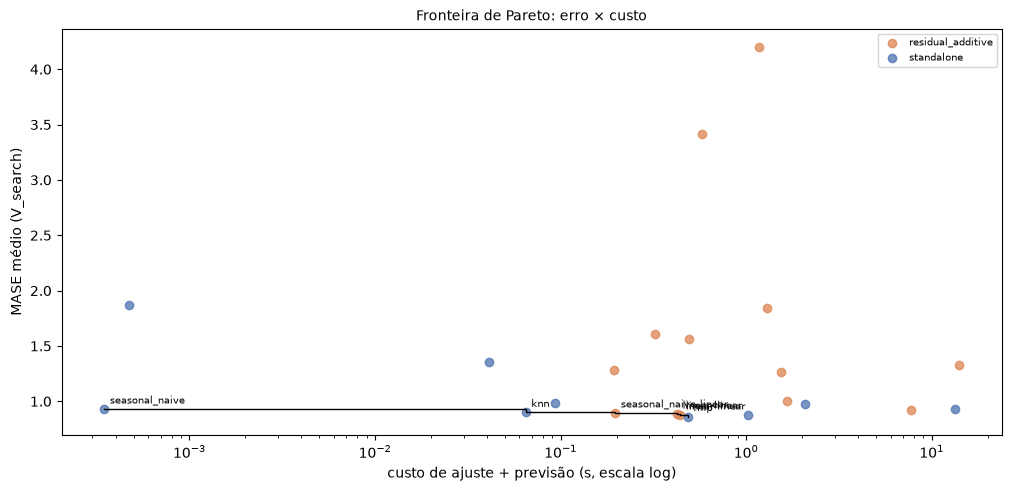

In [6]:
result.plot("pareto")  # error on V_search × cost of each candidate

In [7]:
best = result.best
best

CandidateSpec(family='tree', strategy='standalone', base=ModelSpec(name='random_forest', params_json='{"lags":7}'), corrector=None, window_size=None, alpha=None, residual_source=None, variant='A', members=(), options_json='{}', components=(), candidate_id='1f8d8f124a8728e54358f736b6cef1744bd8df58ebf5b13403a2dd2723163f06')

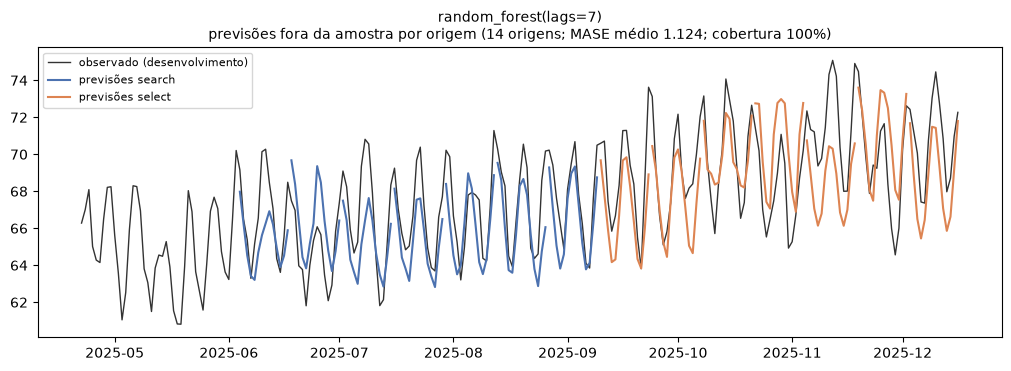

In [8]:
exp.plot_model(best, "cv_forecasts")  # forecasts on the validation origins

## 4. Forecast

`finalize_model` refits the chosen structure on the history before the test, without reopening the selection. `predict_model` forecasts `fh` steps from the end of that history.

In [9]:
final = exp.finalize_model(best)
forecast = exp.predict_model(final)
forecast.predictions

,series_id,origin,horizon,y_pred
timestamp,,,,
2025-12-17,__single__,2025-12-16,1,73.378733
2025-12-18,__single__,2025-12-16,2,71.898770
2025-12-19,__single__,2025-12-16,3,70.122112
2025-12-20,__single__,2025-12-16,4,68.294473
2025-12-21,__single__,2025-12-16,5,68.671440
2025-12-22,__single__,2025-12-16,6,70.818109
2025-12-23,__single__,2025-12-16,7,73.083289
2025-12-24,__single__,2025-12-16,8,73.790339
2025-12-25,__single__,2025-12-16,9,72.286542


## 5. Evaluate on the sealed test

Done only once, after the model is frozen. The result does not go back into the search.

In [10]:
external = exp.evaluate_external(final)
external.metrics

,MASE,MAE,RMSE,sMAPE
model,,,,
random_forest(lags=7),0.704631,1.103425,1.273037,0.015608


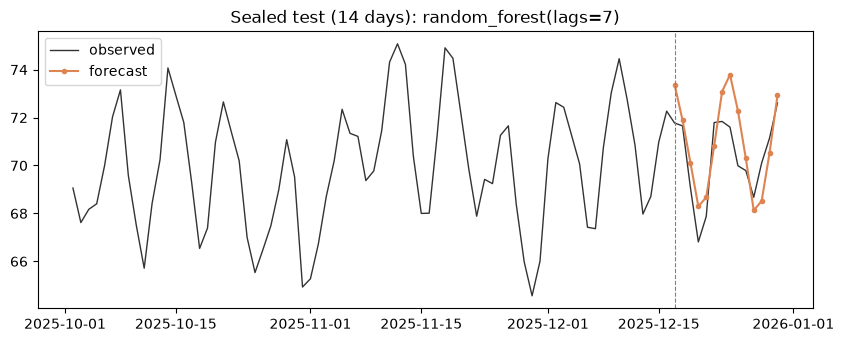

In [11]:
import matplotlib.pyplot as plt

recent = y.iloc[-90:]
predictions = external.predictions
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(recent.index, recent.to_numpy(), color="#333333", linewidth=1, label="observed")
ax.plot(
    predictions.index, predictions["y_pred"], "o-", color="#DD8452", markersize=3, label="forecast"
)
ax.axvline(predictions.index[0], color="gray", linestyle="--", linewidth=0.8)
ax.set_title(f"Sealed test ({len(predictions)} days): {final.spec.label}")
ax.legend()
plt.show()

## Next steps

- `02_hybrid_selection.ipynb`: how the search builds the hybrids and why the champion was chosen.
- `03_finalize_and_persist.ipynb`: save, load and forecast without a sealed test.
- `04_rolling_one_step.ipynb`: variant B, one-step forecasting with observations arriving.
- `05_benchmark_m4.ipynb`: an M4 series with the official test sealed.